In [13]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [14]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [15]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = pd.read_csv("Walmart.csv")
df.head()

,transaction_id,customer_id,product_id,product_name,category,quantity_sold,unit_price,transaction_date,store_id,store_location,...,customer_loyalty_level,payment_method,promotion_applied,promotion_type,weather_conditions,holiday_indicator,weekday,stockout_indicator,forecasted_demand,actual_demand
0,1,2824,843,Fridge,Electronics,3,188.46,3/31/2024 21:46,3,"Miami, FL",...,Silver,Credit Card,True,NaN,Stormy,False,Friday,True,172,179
1,2,1409,135,TV,Electronics,4,1912.04,7/28/2024 12:45,5,"Dallas, TX",...,Gold,Cash,True,Percentage Discount,Rainy,False,Monday,True,109,484
2,3,5506,391,Fridge,Electronics,4,1377.75,06-10-2024 04:55,1,"Los Angeles, CA",...,Platinum,Cash,False,NaN,Sunny,False,Tuesday,True,289,416
3,4,5012,710,Smartphone,Electronics,5,182.31,8/15/2024 1:03,5,"Miami, FL",...,Silver,Cash,True,Percentage Discount,Sunny,True,Sunday,False,174,446
4,5,4657,116,Laptop,Electronics,3,499.28,9/13/2024 0:45,6,"Chicago, IL",...,Bronze,Digital Wallet,False,NaN,Sunny,False,Thursday,True,287,469


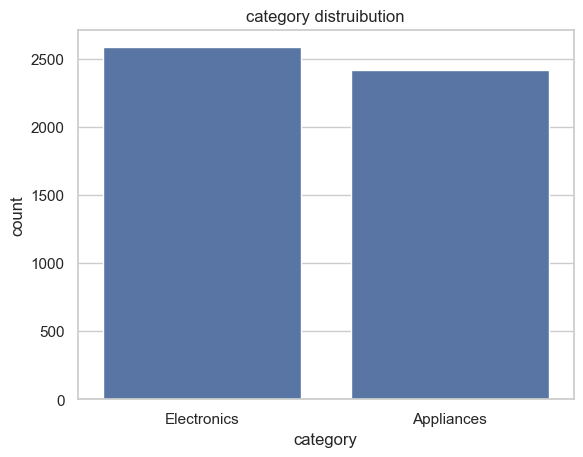

In [18]:
sns.countplot(x="category",data=df)
plt.title("category distruibution")
plt.show()

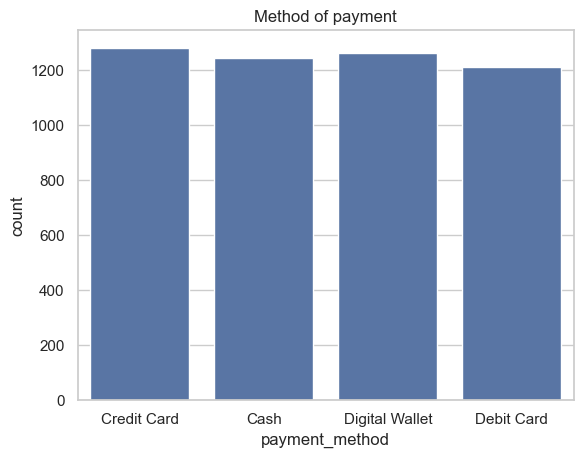

In [19]:
sns.countplot(x="payment_method",data=df)
plt.title("Method of payment")
plt.show()

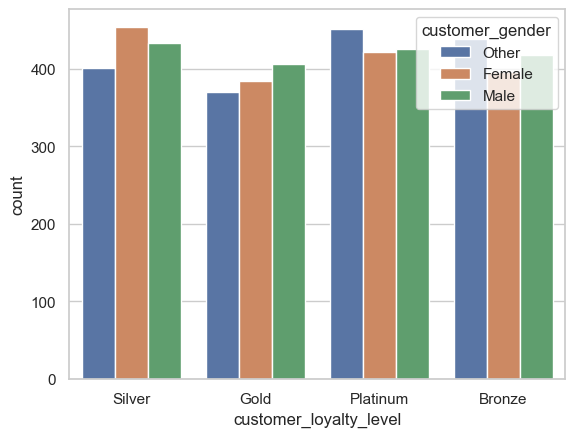

In [20]:
sns.countplot(x="customer_loyalty_level",hue="customer_gender",data=df)
plt.show()

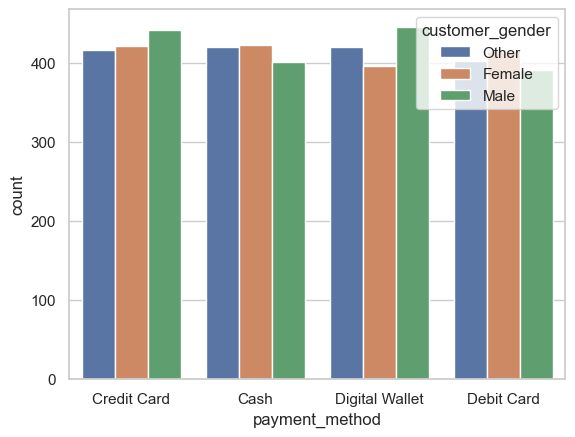

In [21]:
sns.countplot(x="payment_method",hue="customer_gender",data=df)
plt.show()

In [22]:
# Step 1 - Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style
plt.style.use('default')
sns.set_theme(style='whitegrid')

In [24]:
# Step 2: Load Dataset
file_path = 'Walmart.csv'
df = pd.read_csv(file_path)

# Show first 5 rows
print(df.head())

   transaction_id  customer_id  product_id product_name     category  \
0               1         2824         843       Fridge  Electronics   
1               2         1409         135           TV  Electronics   
2               3         5506         391       Fridge  Electronics   
3               4         5012         710   Smartphone  Electronics   
4               5         4657         116       Laptop  Electronics   

   quantity_sold  unit_price  transaction_date  store_id   store_location  \
0              3      188.46   3/31/2024 21:46         3        Miami, FL   
1              4     1912.04   7/28/2024 12:45         5       Dallas, TX   
2              4     1377.75  06-10-2024 04:55         1  Los Angeles, CA   
3              5      182.31    8/15/2024 1:03         5        Miami, FL   
4              3      499.28    9/13/2024 0:45         6      Chicago, IL   

   ...  customer_loyalty_level  payment_method  promotion_applied  \
0  ...                  Silver     

In [25]:
# Step 3: Dataset Information
# Shape
print('Shape of Dataset:', df.shape)

# Columns
print(df.columns)

# Data Types
print(df.dtypes)

# Null Values
print(df.isnull().sum())

# Statistical Summary
print(df.describe())

Shape of Dataset: (5000, 28)
Index(['transaction_id', 'customer_id', 'product_id', 'product_name',
       'category', 'quantity_sold', 'unit_price', 'transaction_date',
       'store_id', 'store_location', 'inventory_level', 'reorder_point',
       'reorder_quantity', 'supplier_id', 'supplier_lead_time', 'customer_age',
       'customer_gender', 'customer_income', 'customer_loyalty_level',
       'payment_method', 'promotion_applied', 'promotion_type',
       'weather_conditions', 'holiday_indicator', 'weekday',
       'stockout_indicator', 'forecasted_demand', 'actual_demand'],
      dtype='str')
transaction_id              int64
customer_id                 int64
product_id                  int64
product_name                  str
category                      str
quantity_sold               int64
unit_price                float64
transaction_date              str
store_id                    int64
store_location                str
inventory_level             int64
reorder_point        

In [26]:
# Step 4: Data Cleaning
# Convert transaction date to datetime
df['transaction_date'] = pd.to_datetime(df['transaction_date'], errors='coerce')

# Create Revenue Column
df['Revenue'] = df['quantity_sold'] * df['unit_price']

# Remove null values
df.dropna(inplace=True)

# Check cleaned data
print(df.head())

    transaction_id  customer_id  product_id product_name     category  \
1                2         1409         135           TV  Electronics   
3                4         5012         710   Smartphone  Electronics   
6                7         2679         238       Laptop   Appliances   
7                8         9935         409       Tablet  Electronics   
19              20         7873         382           TV   Appliances   

    quantity_sold  unit_price    transaction_date  store_id   store_location  \
1               4     1912.04 2024-07-28 12:45:00         5       Dallas, TX   
3               5      182.31 2024-08-15 01:03:00         5        Miami, FL   
6               3     1904.70 2024-03-17 22:33:00         3       Dallas, TX   
7               4      875.16 2024-07-22 13:57:00        16  Los Angeles, CA   
19              3     1155.98 2024-07-21 20:20:00         3        Miami, FL   

    ...  payment_method  promotion_applied       promotion_type  \
1   ...      

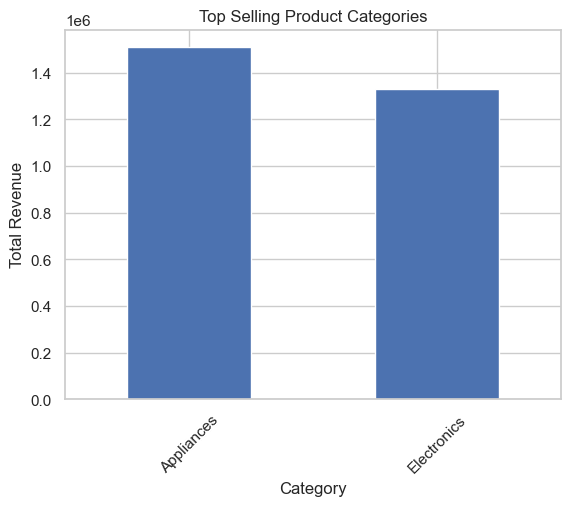

In [27]:
# Step 5: Top Selling Product Categories
category_sales = df.groupby('category')['Revenue'].sum().sort_values(ascending=False)

#plt.figure(figsize=(10,6))
category_sales.plot(kind='bar')
plt.title('Top Selling Product Categories')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

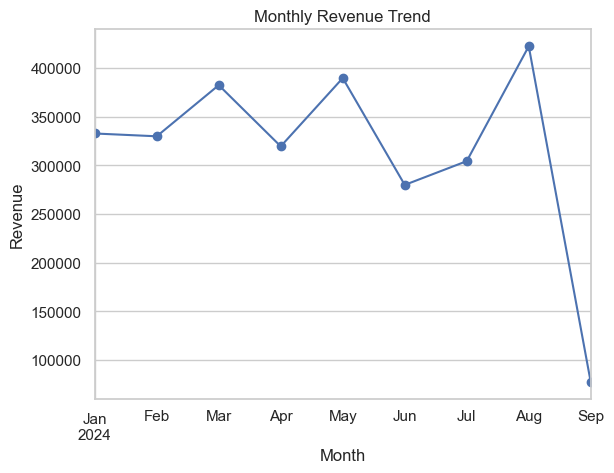

In [28]:
# Step 6: Monthly Revenue Trend
# Extract month
df['Month'] = df['transaction_date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Revenue'].sum()

#plt.figure(figsize=(12,6))
monthly_sales.plot(marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

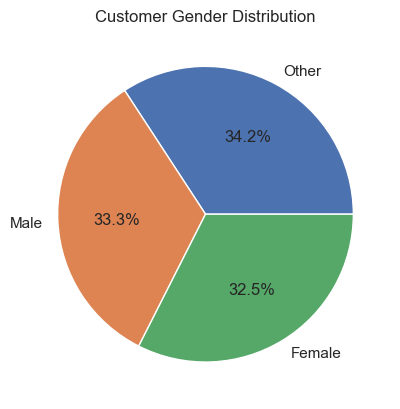

In [29]:
# Step 7: Customer Gender Distribution
#plt.figure(figsize=(6,6))

df['customer_gender'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Customer Gender Distribution')
plt.ylabel('')
plt.show()

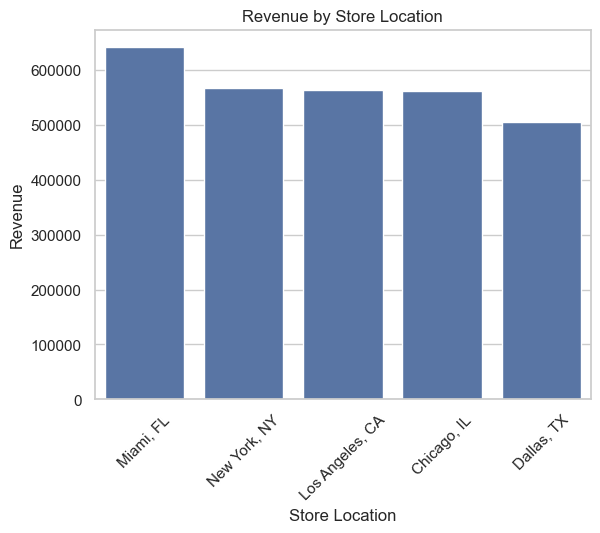

In [59]:
# Step 8: Revenue by Store Location
store_revenue = df.groupby('store_location')['Revenue'].sum().sort_values(ascending=False)

#plt.figure(figsize=(12,6))
sns.barplot(x=store_revenue.index, y=store_revenue.values)
plt.title('Revenue by Store Location')
plt.xlabel('Store Location')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

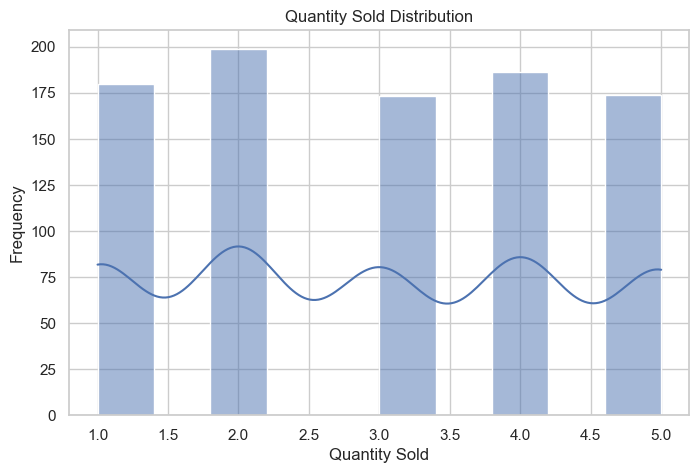

In [64]:
# Step 9: Quantity Sold Distribution
plt.figure(figsize=(8,5))

sns.histplot(df['quantity_sold'], bins=10, kde=True)

plt.title('Quantity Sold Distribution')
plt.xlabel('Quantity Sold')
plt.ylabel('Frequency')
plt.show()

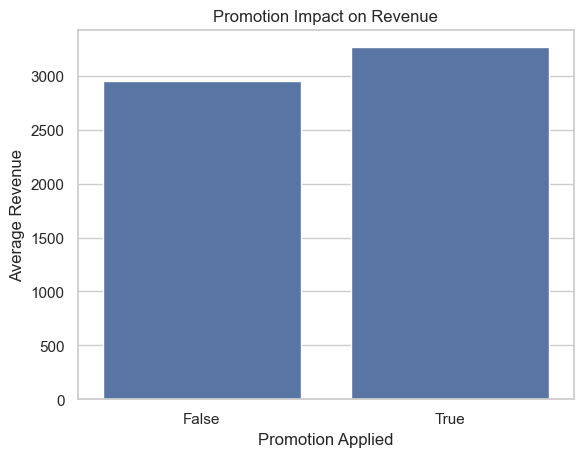

In [56]:
# Step 10: Promotion Impact on Revenue
promotion_sales = df.groupby('promotion_applied')['Revenue'].mean()

#plt.figure(figsize=(6,5))

sns.barplot(x=promotion_sales.index.astype(str), y=promotion_sales.values)

plt.title('Promotion Impact on Revenue')
plt.xlabel('Promotion Applied')
plt.ylabel('Average Revenue')
plt.show()

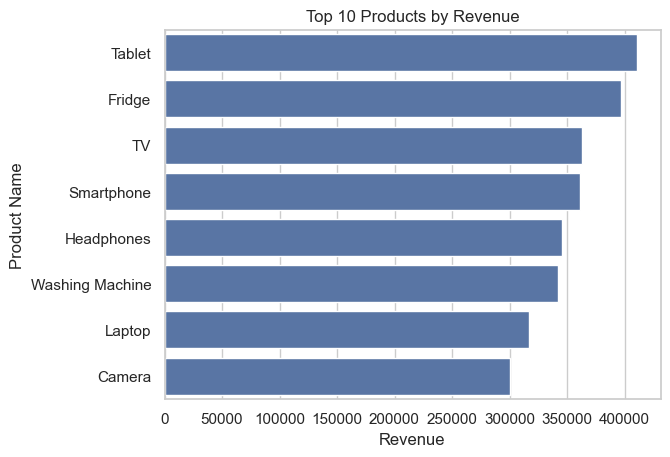

In [55]:
# Step 11: Top 10 Products by Revenue
product_sales = df.groupby('product_name')['Revenue'].sum().sort_values(ascending=False).head(10)

#plt.figure(figsize=(10,6))

sns.barplot(x=product_sales.values, y=product_sales.index)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product Name')
plt.show()

In [54]:
# Bonus: Save Cleaned Dataset
df.to_csv('Cleaned_Walmart_Data.csv', index=False)

print('Dataset Saved Successfully')

Dataset Saved Successfully
